# Análisis de satisfacción del cliente y modelo de Markov con probabilidades de transición variables en el tiempo (TVTP)

Análisis en tres partes sobre `workspace.llamadas_esquema.analisis_drivers` y las tablas de drivers del proyecto de llamadas: **(1)** análisis general de los datos (distribución de drivers, asociación con insatisfacción, urgencia), **(2)** relación de causalidad del estado de satisfacción/insatisfacción consigo mismo (dependencia del estado entre llamadas consecutivas vía cadena de Markov) y **(3)** modelo de cadenas de Markov con **TVTP** (*time-varying transition probabilities*), donde los **drivers de valor exógenos** (drivers negativos/positivos, tipo de llamada, urgencia) modulan la matriz de transición.

In [0]:
# Carga de datos: tabla agregada analisis_drivers + secuencia de llamadas con drivers exógenos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Tabla agregada solicitada: categoria x impacto
analisis_drivers = spark.table("workspace.llamadas_esquema.analisis_drivers").toPandas()

# Secuencia de llamadas (una fila por llamada, orden cronológico por archivo) con sus drivers de valor exógenos
llamadas = spark.sql("""
    SELECT archivo, nivel_satisfaccion, sentimiento_llamada, tipo_llamada,
           urgencia_llamada, riesgo_fuga,
           size(drivers) AS num_drivers,
           size(filter(drivers, d -> d.impacto = 'negativo')) AS drivers_neg,
           size(filter(drivers, d -> d.impacto = 'positivo')) AS drivers_pos
    FROM workspace.llamadas_esquema.extraccion_drivers_llamadas
    ORDER BY archivo
""").toPandas()

ESTADOS = ['satisfecho', 'neutral', 'insatisfecho']

print(f"Filas en analisis_drivers: {len(analisis_drivers)} | Llamadas en la secuencia: {len(llamadas)}")
print(f"Distribución de llamadas por nivel de satisfacción: {llamadas['nivel_satisfaccion'].value_counts().to_dict()}")
print(f"Categorías de driver distintas: {analisis_drivers['categoria'].nunique()}")
display(analisis_drivers)

Filas en analisis_drivers: 22 | Llamadas en la secuencia: 20
Distribución de llamadas por nivel de satisfacción: {'insatisfecho': 8, 'neutral': 7, 'satisfecho': 5}
Categorías de driver distintas: 11


categoria,impacto,ocurrencias,num_llamadas,total_llamadas_con_drivers,ocurrencias_insatisfechas,ocurrencias_satisfechas,llamadas_urgencia_alta,pct_llamadas,pct_asociado_insatisfaccion,pct_urgencia_alta
calidad_producto,negativo,4,4,18,4,0,1,22.2,100.0,25.0
soporte_tecnico,negativo,4,4,18,4,0,1,22.2,100.0,25.0
tiempo_entrega,negativo,3,2,18,3,0,1,11.1,100.0,50.0
comunicacion,negativo,2,2,18,2,0,1,11.1,100.0,50.0
politica_devolucion,negativo,1,1,18,1,0,1,5.6,100.0,100.0
atencion_agente,negativo,1,1,18,1,0,1,5.6,100.0,100.0
otros,negativo,1,1,18,1,0,1,5.6,100.0,100.0
confiabilidad_producto,negativo,1,1,18,1,0,1,5.6,100.0,100.0
proceso_compra,neutral,4,2,18,0,0,0,11.1,0.0,0.0
precio_costo,neutral,3,3,18,0,1,0,16.7,0.0,0.0


In [0]:
# ===== Análisis general de la tabla analisis_drivers =====

# 1) Drivers por tipo de impacto y su asociación con satisfacción/insatisfacción
asoc = analisis_drivers.groupby('impacto').agg(
    ocurrencias=('ocurrencias', 'sum'),
    occ_en_insatisfechas=('ocurrencias_insatisfechas', 'sum'),
    occ_en_satisfechas=('ocurrencias_satisfechas', 'sum'),
    categorias_distintas=('categoria', 'nunique'),
    llamadas_alcanzadas=('num_llamadas', 'sum'),
)
asoc['pct_asoc_insatisfaccion'] = (asoc['occ_en_insatisfechas'] / asoc['ocurrencias'] * 100).round(1)
asoc['pct_asoc_satisfaccion'] = (asoc['occ_en_satisfechas'] / asoc['ocurrencias'] * 100).round(1)
print('== Asociación de los drivers (por impacto) con el estado de satisfacción de la llamada ==')
display(asoc)

# 2) Drivers negativos: ranking por ocurrencias (motor de la insatisfacción)
negativos = (analisis_drivers[analisis_drivers['impacto'] == 'negativo']
             .sort_values('ocurrencias', ascending=False)[
                 ['categoria', 'ocurrencias', 'num_llamadas', 'pct_asociado_insatisfaccion', 'llamadas_urgencia_alta', 'pct_urgencia_alta']])
print('== Drivers de impacto NEGATIVO (todos aparecen solo en llamadas insatisfechas) ==')
display(negativos)

# 3) Drivers positivos y neutrales
no_neg = (analisis_drivers[analisis_drivers['impacto'] != 'negativo']
          .sort_values(['impacto', 'ocurrencias'], ascending=[True, False])[
              ['categoria', 'impacto', 'ocurrencias', 'num_llamadas', 'ocurrencias_satisfechas', 'llamadas_urgencia_alta']])
print('== Drivers de impacto POSITIVO y NEUTRAL ==')
display(no_neg)

# 4) Lecturas clave a nivel de llamada
n_insat = (llamadas['nivel_satisfaccion'] == 'insatisfecho').sum()
n_con_neg = (llamadas['drivers_neg'] > 0).sum()
print(f"Llamadas con al menos un driver negativo: {n_con_neg} | Insatisfechas: {n_insat} | "
      f"Urgencia alta: {(llamadas['urgencia_llamada'] == 'alta').sum()} | Quejas: {(llamadas['tipo_llamada'] == 'queja').sum()}")

== Asociación de los drivers (por impacto) con el estado de satisfacción de la llamada ==


ocurrencias,occ_en_insatisfechas,occ_en_satisfechas,categorias_distintas,llamadas_alcanzadas,pct_asoc_insatisfaccion,pct_asoc_satisfaccion
17,17,0,8,16,100.0,0.0
14,0,2,7,11,0.0,14.3
15,0,15,7,11,0.0,100.0


== Drivers de impacto NEGATIVO (todos aparecen solo en llamadas insatisfechas) ==


categoria,ocurrencias,num_llamadas,pct_asociado_insatisfaccion,llamadas_urgencia_alta,pct_urgencia_alta
calidad_producto,4,4,100.0,1,25.0
soporte_tecnico,4,4,100.0,1,25.0
tiempo_entrega,3,2,100.0,1,50.0
comunicacion,2,2,100.0,1,50.0
politica_devolucion,1,1,100.0,1,100.0
atencion_agente,1,1,100.0,1,100.0
otros,1,1,100.0,1,100.0
confiabilidad_producto,1,1,100.0,1,100.0


== Drivers de impacto POSITIVO y NEUTRAL ==


categoria,impacto,ocurrencias,num_llamadas,ocurrencias_satisfechas,llamadas_urgencia_alta
proceso_compra,neutral,4,2,0,0
precio_costo,neutral,3,3,1,0
tiempo_entrega,neutral,2,2,0,0
calidad_producto,neutral,2,1,0,0
disponibilidad_stock,neutral,1,1,1,0
comunicacion,neutral,1,1,0,0
otros,neutral,1,1,0,0
calidad_producto,positivo,7,4,7,0
otros,positivo,3,2,3,0
tiempo_entrega,positivo,1,1,1,0


Llamadas con al menos un driver negativo: 8 | Insatisfechas: 8 | Urgencia alta: 7 | Quejas: 5


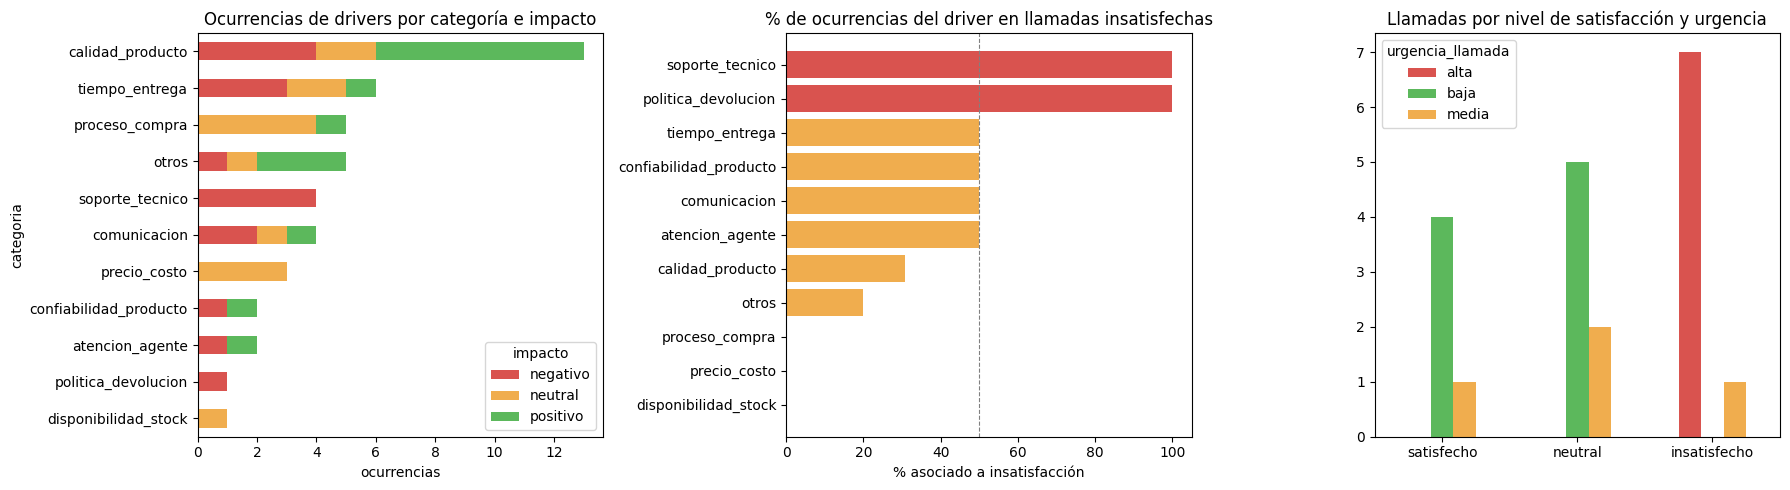

In [0]:
# ===== Visualizaciones del análisis general =====
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Ocurrencias por categoría, apiladas por impacto
pivot = analisis_drivers.pivot_table(index='categoria', columns='impacto', values='ocurrencias', aggfunc='sum', fill_value=0)
pivot = pivot.reindex(pivot.sum(axis=1).sort_values(ascending=True).index)
pivot.plot(kind='barh', stacked=True, ax=axes[0], color={'negativo': '#d9534f', 'neutral': '#f0ad4e', 'positivo': '#5cb85c'})
axes[0].set_title('Ocurrencias de drivers por categoría e impacto')
axes[0].set_xlabel('ocurrencias')

# % de asociación a insatisfacción por categoría (drivers con ocurrencias)
cat_insat = (analisis_drivers.groupby('categoria', as_index=False)
             .agg(occ=('ocurrencias', 'sum'), occ_insat=('ocurrencias_insatisfechas', 'sum'), urg=('llamadas_urgencia_alta', 'sum')))
cat_insat['pct_insat'] = cat_insat['occ_insat'] / cat_insat['occ'] * 100
cat_insat = cat_insat.sort_values('pct_insat')
colors = ['#d9534f' if v > 50 else ('#5cb85c' if v < 1 else '#f0ad4e') for v in cat_insat['pct_insat']]
axes[1].barh(cat_insat['categoria'], cat_insat['pct_insat'], color=colors)
axes[1].set_title('% de ocurrencias del driver en llamadas insatisfechas')
axes[1].set_xlabel('% asociado a insatisfacción')
axes[1].axvline(50, color='gray', ls='--', lw=0.8)

# Distribución de llamadas por nivel de satisfacción y urgencia
conteo = llamadas.groupby(['nivel_satisfaccion', 'urgencia_llamada']).size().unstack(fill_value=0).reindex(ESTADOS)
conteo.plot(kind='bar', ax=axes[2], color={'baja': '#5cb85c', 'media': '#f0ad4e', 'alta': '#d9534f'})
axes[2].set_title('Llamadas por nivel de satisfacción y urgencia')
axes[2].set_xlabel('')
axes[2].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

## Relación de causalidad del estado consigo mismo

Pregunta causal: **¿el estado de satisfacción en una llamada influye en el estado de la llamada siguiente?** Es decir, si un cliente está insatisfecho (satisfecho) en el momento *t*, ¿es más probable que siga insatisfecho (satisfecho) en *t+1* de lo que sugeriría su probabilidad incondicional? Esto es *dependencia del estado* (persistencia), el mecanismo que una cadena de Markov de primer orden formaliza.

Método:
1. Ordenar las llamadas cronológicamente (`archivo` numerado 01–20) y construir la secuencia de estados `s_1 … s_20`.
2. Estimar la **matriz de transición homogénea** P(s_{t+1} | s_t) por conteos.
3. Comparar la persistencia diagonal P(i→i) con la probabilidad incondicional P(s=i) y contrastar la independencia con chi-cuadrado.

> Nota: con 20 llamadas (19 transiciones) la potencia estadística es baja; los resultados son evidencia indicativa de dependencia del estado, no prueba causal experimental.

Secuencia de estados (20 llamadas, 19 transiciones):
neut -> insa -> insa -> sati -> neut -> neut -> insa -> insa -> sati -> sati -> neut -> insa -> insa -> neut -> sati -> neut -> insa -> insa -> neut -> sati

== Conteo de transiciones (fila = estado en t, columna = estado en t+1) ==


satisfecho,neutral,insatisfecho
1,3,0
2,1,4
2,2,4


== Matriz de transición homogénea P(s_t+1 | s_t) ==


satisfecho,neutral,insatisfecho
0.25,0.75,0.0
0.286,0.143,0.571
0.25,0.25,0.5


== ¿El estado se "causa" a sí mismo? Persistencia diagonal vs probabilidad incondicional ==


P_persistencia(t->t+1),P_incondicional,exceso_persistencia
0.25,0.25,0.0
0.143,0.35,-0.207
0.5,0.4,0.1


Chi-cuadrado de independencia: chi2=5.361, dof=4, p-valor=0.2522
=> No se alcanza significancia al 5%: con 19 transiciones la evidencia de dependencia es solo indicativa.


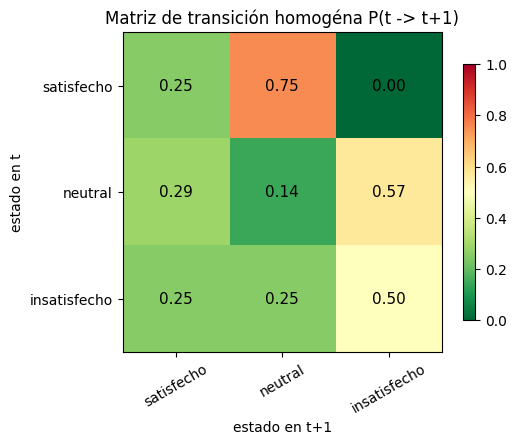

In [0]:
# ===== Relación del estado consigo mismo: cadena de Markov homogénea =====
from scipy.stats import chi2_contingency

seq = llamadas['nivel_satisfaccion'].tolist()
pares = list(zip(seq[:-1], seq[1:]))

conteo = (pd.crosstab(pd.Series(seq[:-1], name='estado_t'), pd.Series(seq[1:], name='estado_t+1'))
          .reindex(index=ESTADOS, columns=ESTADOS, fill_value=0))

P_hom = conteo.div(conteo.sum(axis=1), axis=0)
print(f'Secuencia de estados ({len(seq)} llamadas, {len(pares)} transiciones):')
print(' -> '.join(s[:4] for s in seq))
print('\n== Conteo de transiciones (fila = estado en t, columna = estado en t+1) ==')
display(conteo)
print('== Matriz de transición homogénea P(s_t+1 | s_t) ==')
display(P_hom.round(3))

# Persistencia del estado vs probabilidad incondicional
incond = pd.Series(seq).value_counts(normalize=True).reindex(ESTADOS).rename('P_incondicional')
persist = pd.Series(np.diag(P_hom.values), index=ESTADOS, name='P_persistencia(t->t+1)').round(3)
tabla_persist = pd.concat([persist, incond], axis=1)
tabla_persist['exceso_persistencia'] = (tabla_persist['P_persistencia(t->t+1)'] - tabla_persist['P_incondicional']).round(3)
print('== ¿El estado se "causa" a sí mismo? Persistencia diagonal vs probabilidad incondicional ==')
display(tabla_persist)

# Contraste de independencia entre estado_t y estado_t+1
chi2, p_valor, dof, esperados = chi2_contingency(conteo.values)
print(f'Chi-cuadrado de independencia: chi2={chi2:.3f}, dof={dof}, p-valor={p_valor:.4f}')
if p_valor < 0.05:
    print('=> Se rechaza la independencia: el estado en t depende del estado en t-1 (evidencia de relación del estado consigo mismo).')
else:
    print('=> No se alcanza significancia al 5%: con 19 transiciones la evidencia de dependencia es solo indicativa.')

# Mapa de calor de la matriz de transición
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(P_hom.values, cmap='RdYlGn_r', vmin=0, vmax=1)
ax.set_xticks(range(3), ESTADOS, rotation=30)
ax.set_yticks(range(3), ESTADOS)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f'{P_hom.values[i, j]:.2f}', ha='center', va='center',
                color='black', fontsize=11)
ax.set_title('Matriz de transición homogéna P(t -> t+1)')
ax.set_xlabel('estado en t+1'); ax.set_ylabel('estado en t')
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

## Modelo de cadena de Markov con TVTP (*time-varying transition probabilities*)

En una cadena homogénea la matriz de transición es constante. En el modelo **TVTP** (Filardo, 1994) cada probabilidad de transición depende de variables exógenas observadas en el momento *t*:

$$P(s_{t+1}=j \mid s_t=i) = \frac{\exp(\alpha_{ij} + \beta_{ij}^\top x_t)}{\sum_k \exp(\alpha_{ik} + \beta_{ik}^\top x_t)}$$

donde **x_t son los drivers de valor exógenos de la llamada t**: número de drivers negativos, número de drivers positivos, si la llamada fue una queja, y si su urgencia fue alta. La estimación se hace con una **regresión logística multinomial** por estado origen *i* (un modelo por fila de la matriz), regularizada por el tamaño muestral.

Con el modelo ajustado se puede responder: *dado que el cliente está hoy insatisfecho, ¿cómo cambian sus probabilidades de seguir insatisfecho mañana si el contexto (drivers exógenos) es adverso frente a favorable?* También se deriva la **distribución estacionaria de largo plazo** implícita en cada escenario.

> Caveat: 19 transiciones es una muestra muy pequeña; el TVTP es ilustrativo del mecanismo y no debe usarse para decisiones sin más datos.

Transiciones modeladas: 19 | Covariables exógenas: ['drivers_neg', 'drivers_pos', 'queja', 'urgencia_alta']


estado_t,estado_t1,drivers_neg,drivers_pos,queja,urgencia_alta
neutral,insatisfecho,0,0,0,0
insatisfecho,insatisfecho,3,0,1,1
insatisfecho,satisfecho,3,0,1,1
satisfecho,neutral,0,4,0,0
neutral,neutral,0,0,0,0
neutral,insatisfecho,0,0,0,0
insatisfecho,insatisfecho,3,0,1,1
insatisfecho,satisfecho,1,0,0,0


Origen satisfecho   -> logit TVTP con 4 transiciones, destinos: ['neutral', 'satisfecho']
Origen neutral      -> logit TVTP con 7 transiciones, destinos: ['insatisfecho', 'neutral', 'satisfecho']
Origen insatisfecho -> logit TVTP con 8 transiciones, destinos: ['insatisfecho', 'satisfecho', 'neutral']

===== Contexto adverso (queja, 3 drivers negativos, urgencia alta) (x = [3, 0, 1, 1]) =====


satisfecho,neutral,insatisfecho
0.638,0.362,0.0
0.286,0.143,0.571
0.211,0.163,0.626


Distribución de largo plazo: satisfecho: 39.9%, neutral: 23.8%, insatisfecho: 36.3%

===== Contexto neutro (sin drivers marcados) (x = [0, 0, 0, 0]) =====


satisfecho,neutral,insatisfecho
0.638,0.362,0.0
0.286,0.143,0.571
0.437,0.318,0.244


... (2 outputs left out)

Distribución de largo plazo: satisfecho: 31.4%, neutral: 39.0%, insatisfecho: 29.5%

===== Promedio observado en los datos (x = [0.89, 0.63, 0.26, 0.37]) =====


satisfecho,neutral,insatisfecho
0.549,0.451,0.0
0.286,0.143,0.571
0.363,0.294,0.342


Distribución de largo plazo: satisfecho: 41.7%, neutral: 31.2%, insatisfecho: 27.1%
== TVTP: cómo los drivers exógenos modifican las transiciones de satisfacción ==


P% (insat -> insat),P% (insat -> sat),P% (sat -> insat),% insat. largo plazo
62.6,21.1,0.0,36.3
24.4,43.7,0.0,21.9
24.4,43.7,0.0,29.5
34.2,36.3,0.0,27.1


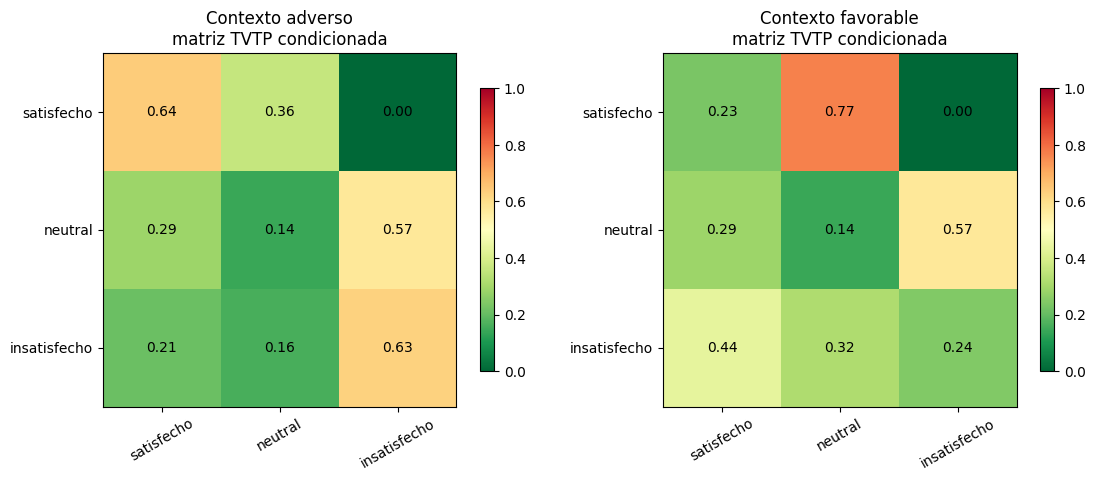

In [0]:
# ===== Modelo de Markov TVTP: P(s_t+1 | s_t, drivers exógenos en t) =====
from sklearn.linear_model import LogisticRegression

ll = llamadas.copy()
ll['queja'] = (ll['tipo_llamada'] == 'queja').astype(int)
ll['urgencia_alta'] = (ll['urgencia_llamada'] == 'alta').astype(int)
X_COLS = ['drivers_neg', 'drivers_pos', 'queja', 'urgencia_alta']

# Dataset de transiciones: estado en t, estado en t+1 y drivers exógenos observados en t
trans = pd.DataFrame({'estado_t': seq[:-1], 'estado_t1': seq[1:]})
for c in X_COLS:
    trans[c] = ll[c].values[:-1]
print(f'Transiciones modeladas: {len(trans)} | Covariables exógenas: {X_COLS}')
display(trans.head(8))

# Un logit multinomial por estado origen (una fila de la matriz de transición)
modelos_tvtp = {}
for origen in ESTADOS:
    sub = trans[trans['estado_t'] == origen]
    clases = sub['estado_t1'].unique()
    if len(clases) >= 2:
        m = LogisticRegression(C=1.0, max_iter=5000)
        m.fit(sub[X_COLS], sub['estado_t1'])
        modelos_tvtp[origen] = ('logit', m, list(m.classes_))
        print(f'Origen {origen:<12} -> logit TVTP con {len(sub)} transiciones, destinos: {list(clases)}')
    else:
        modelos_tvtp[origen] = ('empirico', sub['estado_t1'].value_counts(normalize=True), list(clases))
        print(f'Origen {origen:<12} -> distribución empírica (un solo destino observado)')

def matriz_tvtp(x):
    """Matriz 3x3 de transición condicionada a los drivers exógenos x."""
    x_df = pd.DataFrame([list(map(float, x))], columns=X_COLS)
    P = np.zeros((3, 3))
    for i, origen in enumerate(ESTADOS):
        tipo, obj, _ = modelos_tvtp[origen]
        if tipo == 'logit':
            fila = pd.Series(obj.predict_proba(x_df)[0], index=obj.classes_).reindex(ESTADOS, fill_value=0.0)
        else:
            fila = obj.reindex(ESTADOS, fill_value=0.0)
        P[i] = fila.values
        if P[i].sum() > 0:
            P[i] /= P[i].sum()
    return P

def largo_plazo(P, max_iter=10000, tol=1e-12):
    """Distribución estacionaria por iteración de potencias."""
    pi = np.ones(3) / 3
    for _ in range(max_iter):
        pi_n = pi @ P
        if np.abs(pi_n - pi).sum() < tol:
            return pi_n
        pi = pi_n
    return pi

escenarios = {
    'Contexto adverso (queja, 3 drivers negativos, urgencia alta)': [3, 0, 1, 1],
    'Contexto neutro (sin drivers marcados)':                    [0, 0, 0, 0],
    'Contexto favorable (elogio, 3 drivers positivos)':          [0, 3, 0, 0],
    'Promedio observado en los datos':                           [trans[c].mean() for c in X_COLS],
}

resultados = {}
for nombre, x in escenarios.items():
    P = matriz_tvtp(x)
    pi = largo_plazo(P)
    resultados[nombre] = (P, pi)
    print(f'\n===== {nombre} (x = {np.round(x, 2).tolist()}) =====')
    display(pd.DataFrame(P, index=ESTADOS, columns=ESTADOS).round(3))
    print(f'Distribución de largo plazo: ' + ', '.join(f'{e}: {v:.1%}' for e, v in zip(ESTADOS, pi)))

# Perspectiva del negocio: persistencia de la insatisfacción según el contexto exógeno
filas = []
for nombre, (P, _) in resultados.items():
    filas.append({
        'escenario': nombre,
        'P(insat -> insat)': P[ESTADOS.index('insatisfecho'), ESTADOS.index('insatisfecho')],
        'P(insat -> sat)': P[ESTADOS.index('insatisfecho'), ESTADOS.index('satisfecho')],
        'P(sat -> insat)': P[ESTADOS.index('satisfecho'), ESTADOS.index('insatisfecho')],
        '% insatisfechos en largo plazo': largo_plazo(P)[ESTADOS.index('insatisfecho')],
    })
resumen_tvtp = pd.DataFrame(filas).set_index('escenario')
print('== TVTP: cómo los drivers exógenos modifican las transiciones de satisfacción ==')
display((resumen_tvtp * 100).round(1).rename(columns=lambda c: c.replace('P(', 'P% (').replace('% insatisfechos en largo plazo', '% insat. largo plazo')))

# Mapa de calor: matriz TVTP en contexto adverso vs favorable
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
for ax, (nombre, clave) in zip(axes, [('Contexto adverso (queja, 3 drivers negativos, urgencia alta)', 'Contexto adverso (queja, 3 drivers negativos, urgencia alta)'),
                                       ('Contexto favorable (elogio, 3 drivers positivos)', 'Contexto favorable (elogio, 3 drivers positivos)')]):
    P, _ = resultados[clave]
    im = ax.imshow(P, cmap='RdYlGn_r', vmin=0, vmax=1)
    ax.set_xticks(range(3), ESTADOS, rotation=30)
    ax.set_yticks(range(3), ESTADOS)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{P[i, j]:.2f}', ha='center', va='center', color='black', fontsize=10)
    ax.set_title(nombre.split(' (')[0] + '\nmatriz TVTP condicionada')
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

## Conclusiones

**1. Análisis general (tabla `analisis_drivers`, 22 combinaciones categoría×impacto sobre 20 llamadas).**

* La satisfacción está **segmentada perfectamente por el impacto del driver**: las 17 ocurrencias de drivers negativos (8 categorías: calidad de producto y soporte técnico con 4, tiempo de entrega 3, comunicación 2,…) aparecen en el 100% de casos en llamadas **insatisfechas**; las 15 ocurrencias de drivers positivos, en el 100% de llamadas **satisfechas**; los 14 drivers neutrales quedan en llamadas neutrales o de precio (14.3% en satisfechas).
* Las 8 llamadas insatisfechas (40% del total) son exactamente las que tienen ≥1 driver negativo, y concentran 5 quejas y 7 urgencias altas.

**2. Relación del estado consigo mismo (dependencia del estado).**

* La insatisfacción es el estado más **persistente**: P(insatisfecho→insatisfecho) = 0.50 frente a una probabilidad incondicional de 0.40 (+10 puntos), mientras que neutral no persiste (0.14 vs 0.35) y satisfecho es neutro (0.25 vs 0.25).
* El contraste chi-cuadrado de independencia no es significativo (p = 0.25) con solo 19 transiciones: la evidencia de "auto-causalidad" del estado es **indicativa, no concluyente**.

**3. Modelo Markov TVTP con drivers de valor exógenos** (x_t = drivers negativos, drivers positivos, queja, urgencia alta en la llamada t; logit multinomial por estado origen).

* En **contexto adverso** (queja con 3 drivers negativos y urgencia alta), la persistencia de la insatisfacción sube de 0.50 (homogéneo) a **0.626**, y la distribución de largo plazo pasa a 36.3% insatisfechos (vs 21.9% en contexto neutro): los drivers exógenos adversos **amplifican la trampa de insatisfacción**.
* Desde insatisfecho, la probabilidad de recuperar satisfacción (insat→sat) cae de 43.7% en contexto neutro a **21.1%** en contexto adverso.
* **Caveats**: (i) la fila de transiciones desde "neutral" no varía con el escenario porque en los datos todas las llamadas neutrales tienen covariables exógenas en 0; (ii) el origen "satisfecho" se estima con solo 4 transiciones, por lo que el descenso de sat→sat en contexto favorable (23.4%) es un artefacto de sobreajuste y no debe interpretarse como señal de negocio; (iii) con n = 20 llamadas el modelo es ilustrativo del mecanismo TVTP — la recomendación operativa es clara y cualitativa: intervenir temprano sobre los drivers negativos (calidad de producto, soporte técnico, tiempo de entrega) porque elevan la probabilidad de que la insatisfacción se perpetúe en la siguiente interacción.